In [2]:
import micropip

print("Micropip is ready!")


Micropip is ready!


In [3]:
await micropip.install("pandas")
await micropip.install("numpy")
await micropip.install("matplotlib")
await micropip.install("seaborn")

print("Basic libraries installed successfully!")

Basic libraries installed successfully!


In [4]:
await micropip.install("scikit-learn")
await micropip.install("plotly")

print("Machine Learning libraries installed successfully!")

Machine Learning libraries installed successfully!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import plotly.express as px

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("All libraries imported successfully!")

Pandas: 3.0.2
NumPy: 2.4.6
Scikit-learn: 1.8.0
All libraries imported successfully!


In [6]:
import pandas as pd

df = pd.read_csv("ncr_ride_bookings.csv")

print("Uber India Dataset Loaded Successfully!")

display(df.head())

Uber India Dataset Loaded Successfully!


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (150000, 21)

Column Names:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  str    
 1   Time                               150000 non-null  str    
 2   Booking ID                         150000 non-null  str    
 3   Booking Status                     150000 non-null  str    
 4   Customer ID                        15

In [8]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

,Missing Values,Missing Percentage
Date,0,0.0
Time,0,0.0
Booking ID,0,0.0
Booking Status,0,0.0
Customer ID,0,0.0
Vehicle Type,0,0.0
Pickup Location,0,0.0
Drop Location,0,0.0
Avg VTAT,10500,7.0
Avg CTAT,48000,32.0


In [9]:
# Create a working copy
df_clean = df.copy()

# Remove duplicate bookings
df_clean = df_clean.drop_duplicates(subset="Booking ID")

# Fill missing cancellation and incomplete-ride details
columns_to_fill = [
    "Cancelled Rides by Customer",
    "Reason for cancelling by Customer",
    "Cancelled Rides by Driver",
    "Driver Cancellation Reason",
    "Incomplete Rides",
    "Incomplete Rides Reason"
]

df_clean[columns_to_fill] = df_clean[columns_to_fill].fillna("Not Applicable")

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate bookings removed:", len(df) - len(df_clean))


Original dataset shape: (150000, 21)
Cleaned dataset shape: (148767, 21)
Duplicate bookings removed: 1233


In [10]:
# Combine Date and Time
df_clean["DateTime"] = pd.to_datetime(
    df_clean["Date"] + " " + df_clean["Time"],
    errors="coerce"
)

# Extract useful time-based features
df_clean["Hour"] = df_clean["DateTime"].dt.hour
df_clean["Day"] = df_clean["DateTime"].dt.day
df_clean["Month"] = df_clean["DateTime"].dt.month
df_clean["Day Name"] = df_clean["DateTime"].dt.day_name()

# Display the updated dataset
display(df_clean[["Date", "Time", "DateTime", "Hour", "Day", "Month", "Day Name"]].head())

print("DateTime conversion completed!")


,Date,Time,DateTime,Hour,Day,Month,Day Name
0,2024-03-23,12:29:38,2024-03-23 12:29:38,12,23,3,Saturday
1,2024-11-29,18:01:39,2024-11-29 18:01:39,18,29,11,Friday
2,2024-08-23,08:56:10,2024-08-23 08:56:10,8,23,8,Friday
3,2024-10-21,17:17:25,2024-10-21 17:17:25,17,21,10,Monday
4,2024-09-16,22:08:00,2024-09-16 22:08:00,22,16,9,Monday


DateTime conversion completed!


Booking Status Summary:


Booking Status
Completed                92248
Cancelled by Driver      26789
Cancelled by Customer    10402
No Driver Found          10401
Incomplete                8927
Name: count, dtype: int64

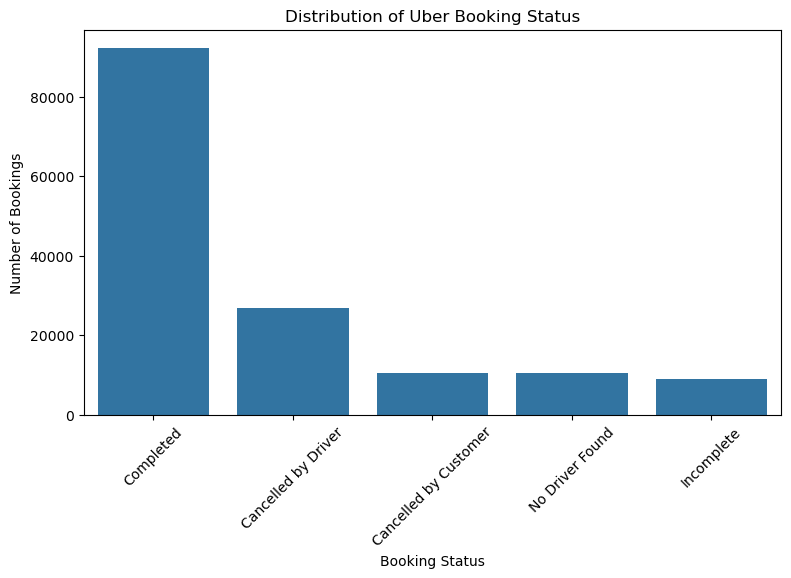

In [11]:
# Count bookings by status
booking_counts = df_clean["Booking Status"].value_counts()

print("Booking Status Summary:")
display(booking_counts)

# Plot booking status
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clean,
    x="Booking Status",
    order=df_clean["Booking Status"].value_counts().index
)

plt.title("Distribution of Uber Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

Bookings by Hour:


Hour
0      1365
1      1347
2      1321
3      1374
4      1311
5      2764
6      4129
7      5401
8      6806
9      8170
10     9490
11     8309
12     6943
13     5431
14     6963
15     8139
16     9565
17    10962
18    12298
19    10963
20     9549
21     8031
22     5397
23     2739
Name: count, dtype: int64

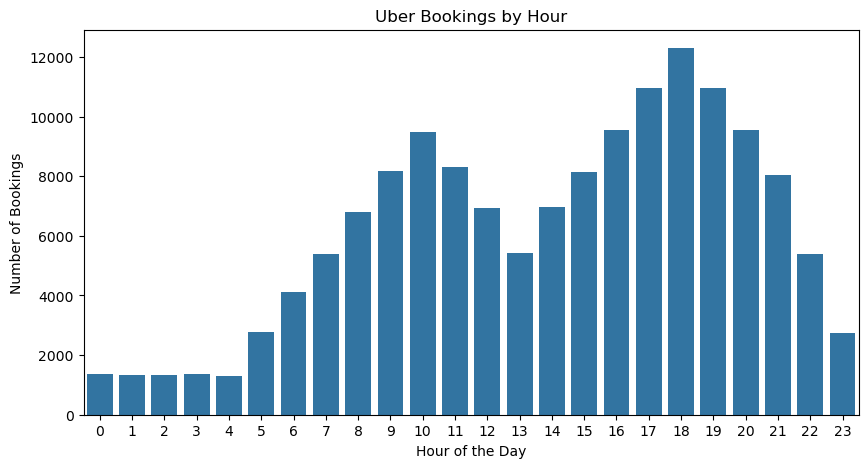

In [12]:
# Count bookings for each hour
hourly_bookings = df_clean["Hour"].value_counts().sort_index()

print("Bookings by Hour:")
display(hourly_bookings)

# Plot hourly bookings
plt.figure(figsize=(10, 5))
sns.barplot(x=hourly_bookings.index, y=hourly_bookings.values)

plt.title("Uber Bookings by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Bookings")
plt.xticks(range(24))
plt.show()

Bookings by Vehicle Type:


Vehicle Type
Auto             37129
Go Mini          29556
Go Sedan         26934
Bike             22318
Premier Sedan    17950
eBike            10458
Uber XL           4422
Name: count, dtype: int64

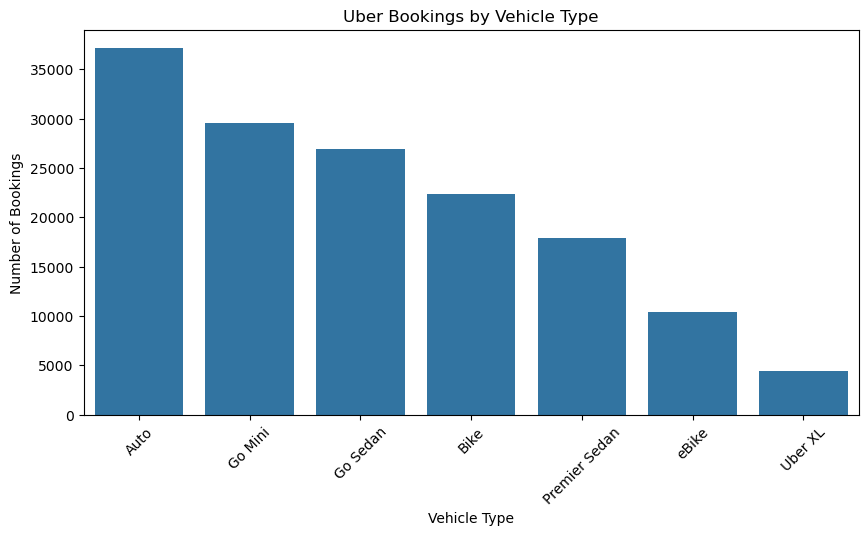

In [13]:
# Count bookings by vehicle type
vehicle_counts = df_clean["Vehicle Type"].value_counts()

print("Bookings by Vehicle Type:")
display(vehicle_counts)

# Plot vehicle type distribution
plt.figure(figsize=(10, 5))
sns.barplot(
    x=vehicle_counts.index,
    y=vehicle_counts.values
)

plt.title("Uber Bookings by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

Payment Method Summary:


Payment Method
UPI            45542
Cash           25157
Uber Wallet    12174
Credit Card    10119
Debit Card      8183
Name: count, dtype: int64

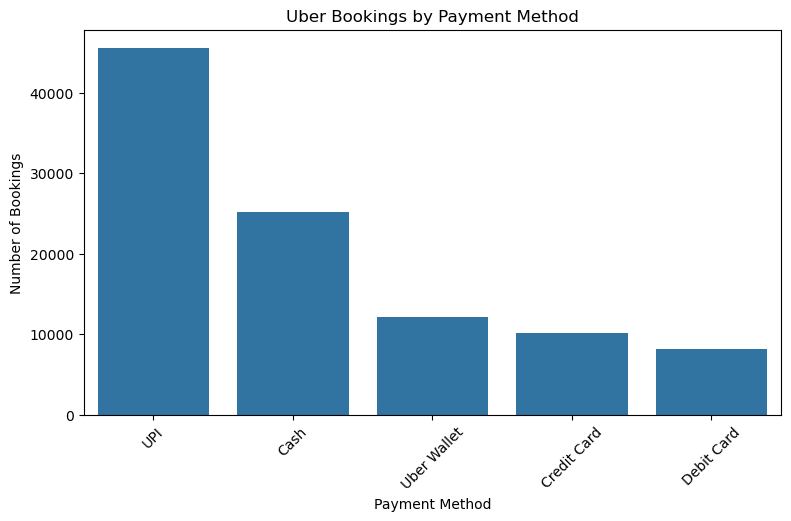

In [14]:
# Count bookings by payment method
payment_counts = df_clean["Payment Method"].value_counts()

print("Payment Method Summary:")
display(payment_counts)

# Plot payment method distribution
plt.figure(figsize=(9, 5))
sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values
)

plt.title("Uber Bookings by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

Booking Value and Ride Distance Summary:


,Booking Value,Ride Distance
count,101175.000000,101175.000000
mean,508.290230,24.640956
std,395.913208,14.002172
min,50.000000,1.000000
25%,234.000000,12.460000
50%,414.000000,23.720000
75%,689.000000,36.820000
max,4277.000000,50.000000


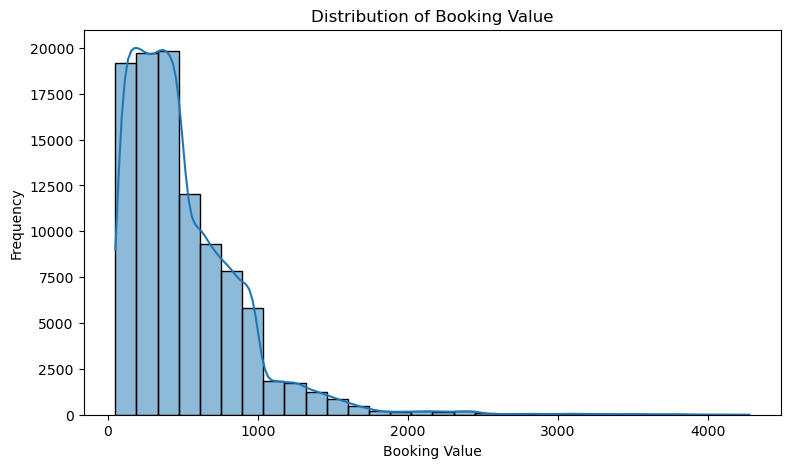

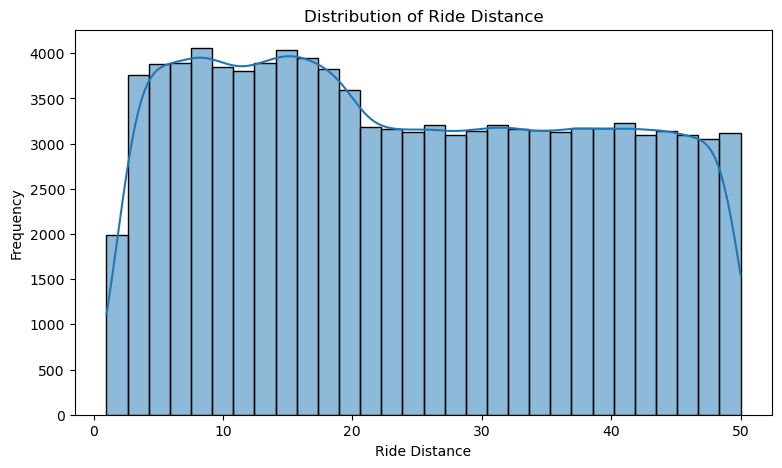

In [15]:
# Statistical summary
print("Booking Value and Ride Distance Summary:")

display(
    df_clean[["Booking Value", "Ride Distance"]].describe()
)

# Plot Booking Value distribution
plt.figure(figsize=(9, 5))
sns.histplot(df_clean["Booking Value"].dropna(), bins=30, kde=True)

plt.title("Distribution of Booking Value")
plt.xlabel("Booking Value")
plt.ylabel("Frequency")
plt.show()

# Plot Ride Distance distribution
plt.figure(figsize=(9, 5))
sns.histplot(df_clean["Ride Distance"].dropna(), bins=30, kde=True)

plt.title("Distribution of Ride Distance")
plt.xlabel("Ride Distance")
plt.ylabel("Frequency")
plt.show()

Correlation Matrix:


,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Hour,Day,Month
Avg VTAT,1.000000,0.062454,0.002310,0.063018,-0.005255,-0.004442,-0.004268,0.002829,0.003328
Avg CTAT,0.062454,1.000000,0.000267,0.101506,0.001129,0.001349,-0.001177,-0.000075,-0.000293
Booking Value,0.002310,0.000267,1.000000,0.005129,-0.000175,-0.000553,-0.001012,0.011386,0.002779
Ride Distance,0.063018,0.101506,0.005129,1.000000,-0.001857,0.004358,-0.002954,0.006252,0.005202
Driver Ratings,-0.005255,0.001129,-0.000175,-0.001857,1.000000,-0.000773,0.000640,-0.000916,-0.001277
Customer Rating,-0.004442,0.001349,-0.000553,0.004358,-0.000773,1.000000,-0.001886,-0.001773,-0.001961
Hour,-0.004268,-0.001177,-0.001012,-0.002954,0.000640,-0.001886,1.000000,-0.003977,0.000581
Day,0.002829,-0.000075,0.011386,0.006252,-0.000916,-0.001773,-0.003977,1.000000,-0.001737
Month,0.003328,-0.000293,0.002779,0.005202,-0.001277,-0.001961,0.000581,-0.001737,1.000000


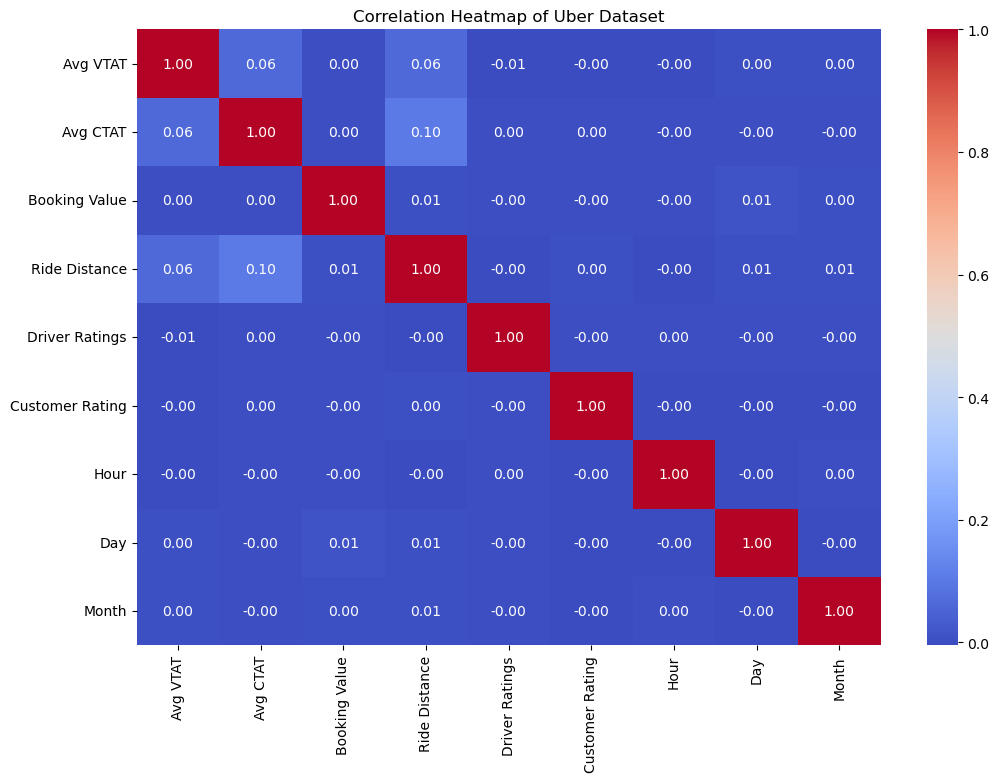

In [16]:
# Select numerical columns
numeric_data = df_clean.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_data.corr()

print("Correlation Matrix:")
display(correlation)

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Uber Dataset")
plt.show()

In [17]:
# Select completed rides with valid booking values
model_data = df_clean[
    (df_clean["Booking Status"] == "Completed") &
    (df_clean["Booking Value"].notna())
].copy()

# Select input features and target
features = [
    "Ride Distance",
    "Avg VTAT",
    "Avg CTAT",
    "Hour",
    "Month"
]

target = "Booking Value"

# Remove rows with missing selected features
model_data = model_data.dropna(subset=features + [target])

X = model_data[features]
y = model_data[target]

print("Model Dataset Shape:", model_data.shape)
print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Model Dataset Shape: (92248, 26)

Input Features:
   Ride Distance  Avg VTAT  Avg CTAT  Hour  Month
2          13.58      13.4      25.8     8      8
3          34.02      13.1      28.5    17     10
4          48.21       5.3      19.6    22      9
5           4.85       5.1      18.1     9      2
6          41.24       7.1      20.4    15      6

Target Values:
2    627.0
3    416.0
4    737.0
5    316.0
6    640.0
Name: Booking Value, dtype: float64


In [18]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (73798, 5)
Testing Data: (18450, 5)
Training Target: (73798,)
Testing Target: (18450,)


In [19]:
from sklearn.linear_model import LinearRegression

# Create the model
reg_model = LinearRegression()

# Train the model
reg_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict booking values
y_pred = reg_model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 283.0403366878456
MSE: 151882.33906646515
RMSE: 389.7208476159123
R2 Score: -0.00034846780799879795


In [22]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [23]:
from sklearn.ensemble import RandomForestRegressor

# Create a lightweight Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=20,
    max_depth=10,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [24]:
# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Evaluation
------------------------
MAE: 283.66315259391223
MSE: 152482.05481980788
RMSE: 390.4895066705479
R2 Score: -0.004298398646989776


,Feature,Importance
0,Ride Distance,0.327198
2,Avg CTAT,0.239579
1,Avg VTAT,0.211292
3,Hour,0.127963
4,Month,0.093967


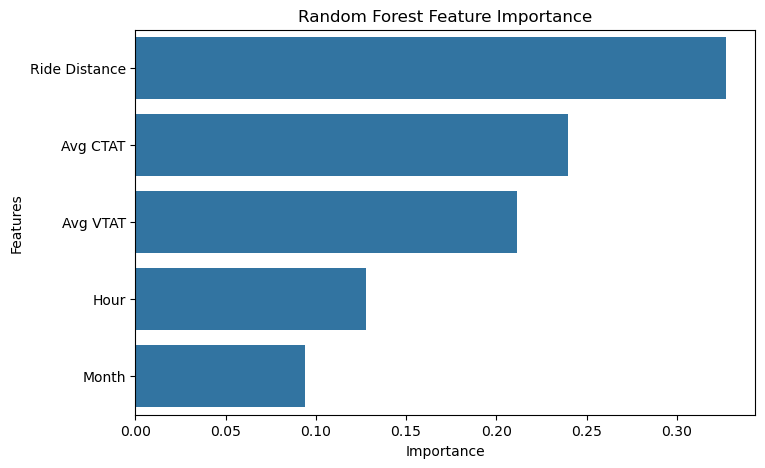

In [25]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

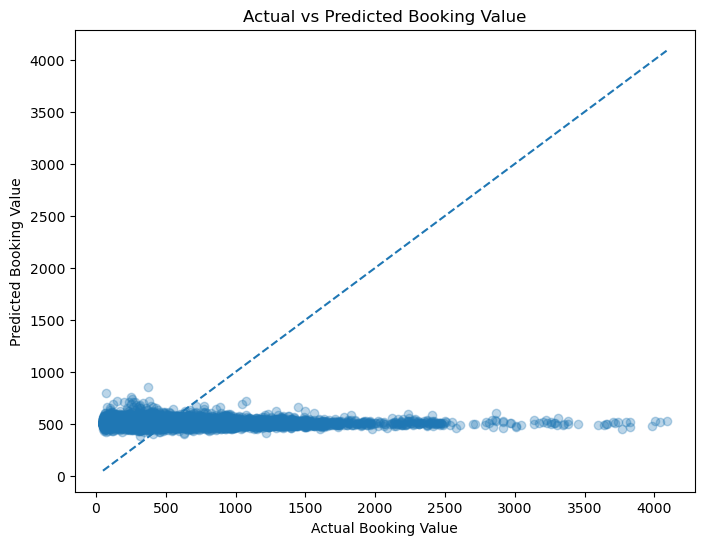

In [26]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.3)

plt.xlabel("Actual Booking Value")
plt.ylabel("Predicted Booking Value")
plt.title("Actual vs Predicted Booking Value")

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [27]:
# Prepare data with additional categorical features
features_new = [
    "Ride Distance",
    "Avg VTAT",
    "Avg CTAT",
    "Hour",
    "Month",
    "Vehicle Type",
    "Payment Method"
]

model_data_new = df_clean[
    (df_clean["Booking Status"] == "Completed") &
    (df_clean["Booking Value"].notna())
].dropna(subset=features_new + ["Booking Value"]).copy()

# Convert categorical columns into numerical columns
model_data_new = pd.get_dummies(
    model_data_new,
    columns=["Vehicle Type", "Payment Method"],
    dtype=int
)

print("New Model Dataset Shape:", model_data_new.shape)
display(model_data_new.head())

New Model Dataset Shape: (92248, 36)


,Date,Time,Booking ID,Booking Status,Customer ID,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,...,Vehicle Type_Go Mini,Vehicle Type_Go Sedan,Vehicle Type_Premier Sedan,Vehicle Type_Uber XL,Vehicle Type_eBike,Payment Method_Cash,Payment Method_Credit Card,Payment Method_Debit Card,Payment Method_UPI,Payment Method_Uber Wallet
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Khandsa,Malviya Nagar,13.4,25.8,Not Applicable,...,0,0,0,0,0,0,0,1,0,0
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Central Secretariat,Inderlok,13.1,28.5,Not Applicable,...,0,0,1,0,0,0,0,0,1,0
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Ghitorni Village,Khan Market,5.3,19.6,Not Applicable,...,0,0,0,0,0,0,0,0,1,0
5,2024-02-06,09:44:56,"""CNR4096693""",Completed,"""CID4670564""",AIIMS,Narsinghpur,5.1,18.1,Not Applicable,...,0,0,0,0,0,0,0,0,1,0
6,2024-06-17,15:45:58,"""CNR2002539""",Completed,"""CID6800553""",Vaishali,Punjabi Bagh,7.1,20.4,Not Applicable,...,1,0,0,0,0,0,0,0,1,0


In [28]:
from sklearn.model_selection import train_test_split

# Select numerical and encoded categorical features
new_features = [
    "Ride Distance",
    "Avg VTAT",
    "Avg CTAT",
    "Hour",
    "Month"
]

new_features += [
    col for col in model_data_new.columns
    if col.startswith("Vehicle Type_")
    or col.startswith("Payment Method_")
]

# Create X and y
X_new = model_data_new[new_features]
y_new = model_data_new["Booking Value"]

# Split into training and testing data
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y_new,
    test_size=0.20,
    random_state=42
)

print("New Features:", len(new_features))
print("Training Data:", X_train_new.shape)
print("Testing Data:", X_test_new.shape)

New Features: 17
Training Data: (73798, 17)
Testing Data: (18450, 17)


In [29]:
from sklearn.ensemble import RandomForestRegressor

# Create improved Random Forest model
rf_model_new = RandomForestRegressor(
    n_estimators=20,
    max_depth=10,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=1
)

# Train the model
rf_model_new.fit(X_train_new, y_train_new)

print("Improved Random Forest Model Trained Successfully!")

Improved Random Forest Model Trained Successfully!


In [31]:
# Make predictions
new_pred = rf_model_new.predict(X_test_new)

# Calculate evaluation metrics
new_mae = mean_absolute_error(y_test_new, new_pred)
new_mse = mean_squared_error(y_test_new, new_pred)
new_rmse = np.sqrt(new_mse)
new_r2 = r2_score(y_test_new, new_pred)

print("Improved Random Forest Evaluation")
print("---------------------------------")
print("MAE:", new_mae)
print("MSE:", new_mse)
print("RMSE:", new_rmse)
print("R2 Score:", new_r2)

Improved Random Forest Evaluation
---------------------------------
MAE: 283.63850277343505
MSE: 152330.03958006267
RMSE: 390.294811110861
R2 Score: -0.003297174850350526


In [32]:
# Create binary booking status
df_class = df_clean.copy()

df_class["Ride Outcome"] = (
    df_class["Booking Status"] == "Completed"
).astype(int)

# Select input features
class_features = [
    "Hour",
    "Day",
    "Month",
    "Vehicle Type"
]

# Prepare dataset
class_data = df_class[class_features + ["Ride Outcome"]].copy()

# Convert Vehicle Type into numerical columns
class_data = pd.get_dummies(
    class_data,
    columns=["Vehicle Type"],
    dtype=int
)

X_class = class_data.drop("Ride Outcome", axis=1)
y_class = class_data["Ride Outcome"]

print("Classification Dataset:", class_data.shape)
print("\nTarget Distribution:")
print(y_class.value_counts())

Classification Dataset: (148767, 11)

Target Distribution:
Ride Outcome
1    92248
0    56519
Name: count, dtype: int64


In [33]:
from sklearn.model_selection import train_test_split

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training Data:", X_train_class.shape)
print("Testing Data:", X_test_class.shape)

print("Training Target:", y_train_class.shape)
print("Testing Target:", y_test_class.shape)

Training Data: (119013, 10)
Testing Data: (29754, 10)
Training Target: (119013,)
Testing Target: (29754,)


In [34]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

# Train the model
dt_model.fit(X_train_class, y_train_class)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Make predictions
y_pred_class = dt_model.predict(X_test_class)

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test_class, y_pred_class))
print("Precision:", precision_score(y_test_class, y_pred_class))
print("Recall:", recall_score(y_test_class, y_pred_class))
print("F1 Score:", f1_score(y_test_class, y_pred_class))

print("\nClassification Report:")
print(classification_report(y_test_class, y_pred_class))

Accuracy: 0.6175304160785104
Precision: 0.6201808662541647
Recall: 0.9887262872628726
F1 Score: 0.7622430218953702

Classification Report:
              precision    recall  f1-score   support

           0       0.39      0.01      0.02     11304
           1       0.62      0.99      0.76     18450

    accuracy                           0.62     29754
   macro avg       0.50      0.50      0.39     29754
weighted avg       0.53      0.62      0.48     29754



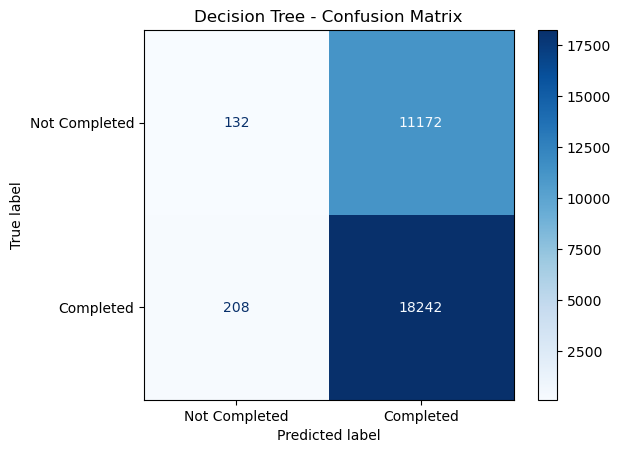

Confusion Matrix:
[[  132 11172]
 [  208 18242]]


In [36]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test_class, y_pred_class)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Completed", "Completed"]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [37]:
from sklearn.tree import DecisionTreeClassifier

dt_model_balanced = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

dt_model_balanced.fit(X_train_class, y_train_class)

print("Balanced Decision Tree trained successfully!")

Balanced Decision Tree trained successfully!


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict using balanced model
y_pred_balanced = dt_model_balanced.predict(X_test_class)

# Evaluation
print("Accuracy:", accuracy_score(y_test_class, y_pred_balanced))
print("Precision:", precision_score(y_test_class, y_pred_balanced))
print("Recall:", recall_score(y_test_class, y_pred_balanced))
print("F1 Score:", f1_score(y_test_class, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_test_class, y_pred_balanced))

Accuracy: 0.5261141359144988
Precision: 0.6258826253038546
Recall: 0.5861246612466124
F1 Score: 0.6053515450067174

Classification Report:
              precision    recall  f1-score   support

           0       0.39      0.43      0.41     11304
           1       0.63      0.59      0.61     18450

    accuracy                           0.53     29754
   macro avg       0.51      0.51      0.51     29754
weighted avg       0.54      0.53      0.53     29754



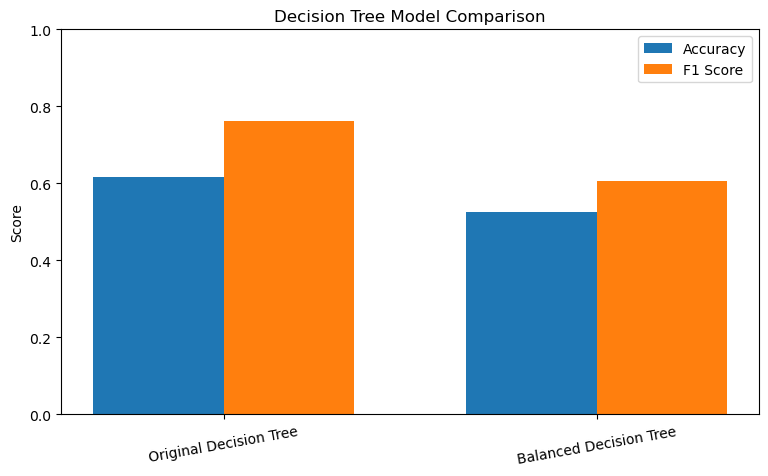

In [39]:
models = ["Original Decision Tree", "Balanced Decision Tree"]

accuracy = [
    accuracy_score(y_test_class, y_pred_class),
    accuracy_score(y_test_class, y_pred_balanced)
]

f1 = [
    f1_score(y_test_class, y_pred_class),
    f1_score(y_test_class, y_pred_balanced)
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, accuracy, width, label="Accuracy")
plt.bar(x + width/2, f1, width, label="F1 Score")

plt.xticks(x, models, rotation=10)
plt.ylabel("Score")
plt.title("Decision Tree Model Comparison")
plt.legend()
plt.ylim(0, 1)
plt.show()

In [40]:
# Group bookings by date
daily_bookings = (
    df_clean.groupby(df_clean["DateTime"].dt.date)
    .size()
    .reset_index(name="Total Bookings")
)

# Display first 10 records
print(daily_bookings.head(10))

print("\nTotal Days:", len(daily_bookings))

     DateTime  Total Bookings
0  2024-01-01             410
1  2024-01-02             386
2  2024-01-03             382
3  2024-01-04             407
4  2024-01-05             414
5  2024-01-06             404
6  2024-01-07             436
7  2024-01-08             386
8  2024-01-09             427
9  2024-01-10             404

Total Days: 365


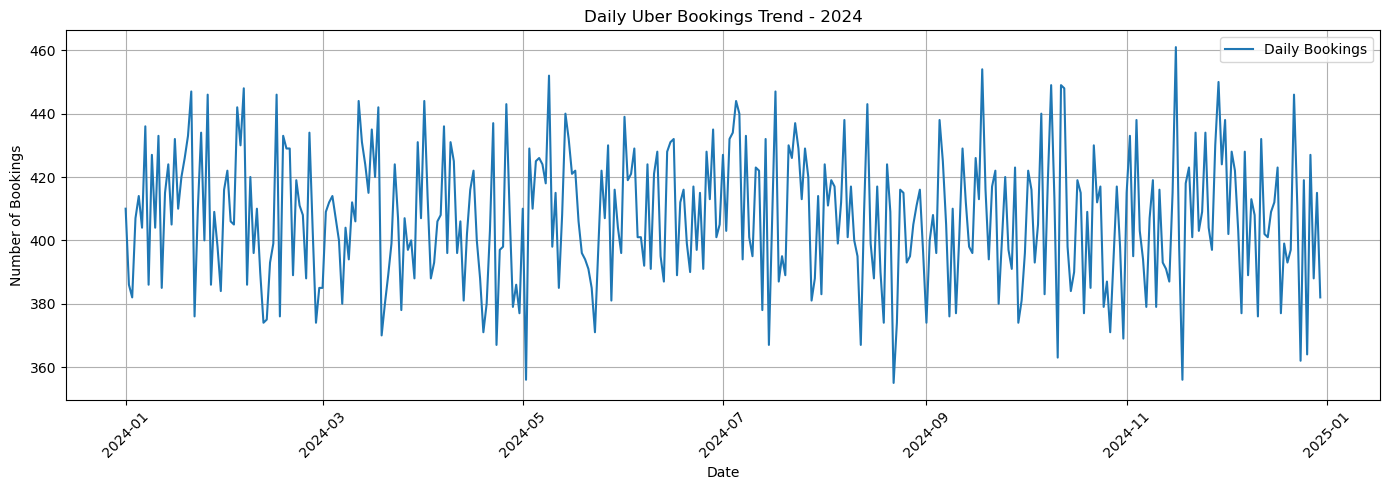

In [41]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_bookings["DateTime"],
    daily_bookings["Total Bookings"],
    label="Daily Bookings"
)

plt.title("Daily Uber Bookings Trend - 2024")
plt.xlabel("Date")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

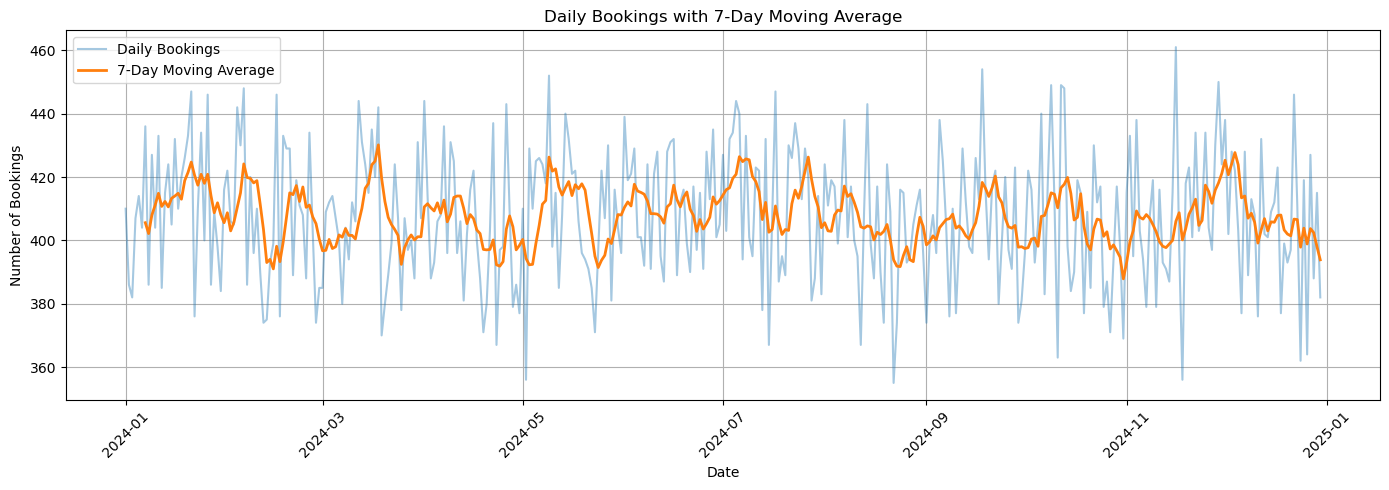

In [42]:
# Calculate 7-day moving average
daily_bookings["7-Day Average"] = (
    daily_bookings["Total Bookings"]
    .rolling(window=7)
    .mean()
)

# Plot daily bookings and moving average
plt.figure(figsize=(14, 5))

plt.plot(
    daily_bookings["DateTime"],
    daily_bookings["Total Bookings"],
    alpha=0.4,
    label="Daily Bookings"
)

plt.plot(
    daily_bookings["DateTime"],
    daily_bookings["7-Day Average"],
    linewidth=2,
    label="7-Day Moving Average"
)

plt.title("Daily Bookings with 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Number of Bookings")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
import micropip

await micropip.install("nbformat")

In [45]:
import nbformat
print("nbformat version:", nbformat.__version__)

nbformat version: 5.11.1


In [47]:
import importlib.util

print("IPython installed:", importlib.util.find_spec("IPython") is not None)
print("nbformat installed:", importlib.util.find_spec("nbformat") is not None)

IPython installed: True
nbformat installed: True


In [48]:
import plotly.io as pio

pio.renderers.default = "iframe"
print("Plotly renderer:", pio.renderers.default)

Plotly renderer: iframe


In [51]:
# Save interactive chart as HTML
fig.write_html("uber_daily_bookings.html")

print("Interactive chart saved successfully!")

Interactive chart saved successfully!


In [52]:
vehicle_bookings = (
    df_clean["Vehicle Type"]
    .value_counts()
    .reset_index()
)

vehicle_bookings.columns = ["Vehicle Type", "Total Bookings"]

fig_vehicle = px.bar(
    vehicle_bookings,
    x="Vehicle Type",
    y="Total Bookings",
    color="Vehicle Type",
    title="Uber Bookings by Vehicle Type",
    text="Total Bookings"
)

fig_vehicle.update_layout(
    template="plotly_white",
    showlegend=False
)

fig_vehicle.write_html("uber_vehicle_bookings.html")

print("Vehicle-wise interactive chart saved successfully!")

Vehicle-wise interactive chart saved successfully!


In [53]:
payment_data = (
    df_clean["Payment Method"]
    .value_counts()
    .reset_index()
)

payment_data.columns = ["Payment Method", "Total Bookings"]

fig_payment = px.pie(
    payment_data,
    names="Payment Method",
    values="Total Bookings",
    title="Uber Bookings by Payment Method",
    hole=0.4
)

fig_payment.write_html("uber_payment_analysis.html")

print("Payment analysis chart saved successfully!")

Payment analysis chart saved successfully!


In [54]:
status_data = (
    df_clean["Booking Status"]
    .value_counts()
    .reset_index()
)

status_data.columns = ["Booking Status", "Total Bookings"]

fig_status = px.bar(
    status_data,
    x="Booking Status",
    y="Total Bookings",
    color="Booking Status",
    text="Total Bookings",
    title="Uber Booking Status Analysis"
)

fig_status.update_layout(
    template="plotly_white",
    showlegend=False
)

fig_status.write_html("uber_booking_status.html")

print("Booking status chart saved successfully!")

Booking status chart saved successfully!


In [55]:
total_bookings = len(df_clean)

completed_bookings = (
    df_clean["Booking Status"] == "Completed"
).sum()

cancelled_bookings = df_clean["Booking Status"].isin([
    "Cancelled by Driver",
    "Cancelled by Customer"
]).sum()

completion_rate = (
    completed_bookings / total_bookings
) * 100

average_booking_value = df_clean["Booking Value"].mean()

average_ride_distance = df_clean["Ride Distance"].mean()

print("UBER RIDE ANALYTICS - DASHBOARD SUMMARY")
print("----------------------------------------")
print("Total Bookings:", total_bookings)
print("Completed Bookings:", completed_bookings)
print("Cancelled Bookings:", cancelled_bookings)
print("Completion Rate:", round(completion_rate, 2), "%")
print("Average Booking Value: ₹", round(average_booking_value, 2))
print("Average Ride Distance:", round(average_ride_distance, 2), "km")

UBER RIDE ANALYTICS - DASHBOARD SUMMARY
----------------------------------------
Total Bookings: 148767
Completed Bookings: 92248
Cancelled Bookings: 37191
Completion Rate: 62.01 %
Average Booking Value: ₹ 508.29
Average Ride Distance: 24.64 km


In [56]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

dashboard = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Daily Booking Trends",
        "Bookings by Vehicle Type",
        "Payment Method Distribution",
        "Booking Status"
    ),
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "domain"}, {"type": "xy"}]
    ]
)

# Daily bookings
for trace in fig.data:
    dashboard.add_trace(trace, row=1, col=1)

# Vehicle bookings
for trace in fig_vehicle.data:
    dashboard.add_trace(trace, row=1, col=2)

# Payment distribution
for trace in fig_payment.data:
    dashboard.add_trace(trace, row=2, col=1)

# Booking status
for trace in fig_status.data:
    dashboard.add_trace(trace, row=2, col=2)

dashboard.update_layout(
    title="UBER RIDE ANALYTICS DASHBOARD - 2024",
    height=850,
    template="plotly_white",
    showlegend=True
)

dashboard.write_html("Uber_Analytics_Dashboard.html")

print("Complete Interactive Dashboard Created Successfully!")

Complete Interactive Dashboard Created Successfully!


In [57]:
import os

files = [
    "Uber_Analytics_Dashboard.html",
    "uber_daily_bookings.html",
    "uber_vehicle_bookings.html",
    "uber_payment_analysis.html",
    "uber_booking_status.html"
]

for file in files:
    print(file, "->", "Created" if os.path.exists(file) else "Not Found")

Uber_Analytics_Dashboard.html -> Created
uber_daily_bookings.html -> Created
uber_vehicle_bookings.html -> Created
uber_payment_analysis.html -> Created
uber_booking_status.html -> Created
